# Viagens a Serviço 2025: camada Gold

Última etapa do pipeline (Raw → Silver → **Gold**). Aqui as tabelas da Silver viram respostas
para as perguntas de negócio, cada uma com consulta SQL, tabela e gráfico.

Está dividido em três partes:

1. **Conferência da Silver**: contagens e integridade referencial.
2. **Perguntas 1 a 3**: respondidas direto da Silver.
3. **Camada Gold** (`gold_*` como tabela e `vw_gold_*` como VIEW, criadas com `JOIN` + `GROUP BY`) e **perguntas 4 a 7**.

Antes de rodar, execute `0_criar_banco.sql`, `1_extrair.py` e `2_transformar.py`.

In [1]:
import textwrap

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sqlalchemy import text

import banco

engine = banco.criar_engine()

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_colwidth = 80
COR = "#1f6f8b"
COR_DESTAQUE = "#d1495b"


def consultar(sql):
    """Roda uma consulta SQL e devolve um DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)


def executar(sql):
    """Roda um comando SQL (CREATE, DROP...) com commit automático."""
    with engine.begin() as conn:
        conn.execute(text(sql))


def inteiro_br(valor):
    return f"{valor:,.0f}".replace(",", ".")


def reais(valor):
    texto = f"{valor:,.2f}".replace(",", "X").replace(".", ",")
    return "R$ " + texto.replace("X", ".")


def reais_curto(valor):
    if abs(valor) >= 1e9:
        return f"R$ {valor / 1e9:.2f} bi".replace(".", ",")
    if abs(valor) >= 1e6:
        return f"R$ {valor / 1e6:.1f} mi".replace(".", ",")
    if abs(valor) >= 1e3:
        return f"R$ {valor / 1e3:.1f} mil".replace(".", ",")
    return f"R$ {valor:.0f}"


def abreviar(texto, largura=55):
    return textwrap.shorten(str(texto), width=largura, placeholder="...")


def barras_horizontais(df, rotulo, valor, titulo, xlabel, ylabel, legenda,
                       arquivo, formato=reais_curto, destacar_primeiro=True):
    """Gráfico de barras horizontais, maior valor no topo."""
    dados = df.iloc[::-1]
    cores = [COR] * len(dados)
    if destacar_primeiro:
        cores[-1] = COR_DESTAQUE
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(dados) + 2.4))
    barras = ax.barh(dados[rotulo], dados[valor], color=cores, label=legenda)
    for barra in barras:
        ax.text(barra.get_width(), barra.get_y() + barra.get_height() / 2,
                "  " + formato(barra.get_width()), va="center", fontsize=9)
    ax.set_title(titulo, fontsize=13, fontweight="bold", loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: formato(v)))
    ax.margins(x=0.18)
    ax.grid(axis="y", visible=False)
    itens = [Patch(color=COR, label=legenda)]
    if destacar_primeiro:
        itens.insert(0, Patch(color=COR_DESTAQUE, label="Maior valor"))
    ax.legend(handles=itens, loc="lower right")
    fig.tight_layout()
    fig.savefig(f"docs/{arquivo}", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Conferência da camada Silver

In [2]:
conferencia = consultar("""
    SELECT 'viagem' AS tabela,
           (SELECT COUNT(*) FROM raw_viagem)    AS linhas_raw,
           (SELECT COUNT(*) FROM silver_viagem) AS linhas_silver
    UNION ALL
    SELECT 'pagamento',
           (SELECT COUNT(*) FROM raw_pagamento),
           (SELECT COUNT(*) FROM silver_pagamento)
    UNION ALL
    SELECT 'passagem',
           (SELECT COUNT(*) FROM raw_passagem),
           (SELECT COUNT(*) FROM silver_passagem)
    UNION ALL
    SELECT 'trecho',
           (SELECT COUNT(*) FROM raw_trecho),
           (SELECT COUNT(*) FROM silver_trecho)
""")
conferencia

,tabela,linhas_raw,linhas_silver
0,viagem,341860,341860
1,pagamento,606916,606916
2,passagem,167260,167260
3,trecho,763349,763349


In [3]:
# Integridade referencial: nenhuma linha filha pode apontar para viagem que não existe
orfas = consultar("""
    SELECT 'pagamento' AS tabela, COUNT(*) AS linhas_orfas
    FROM silver_pagamento p
    LEFT JOIN silver_viagem v ON v.id_viagem = p.id_viagem
    WHERE v.id_viagem IS NULL
    UNION ALL
    SELECT 'passagem', COUNT(*)
    FROM silver_passagem p
    LEFT JOIN silver_viagem v ON v.id_viagem = p.id_viagem
    WHERE v.id_viagem IS NULL
    UNION ALL
    SELECT 'trecho', COUNT(*)
    FROM silver_trecho t
    LEFT JOIN silver_viagem v ON v.id_viagem = t.id_viagem
    WHERE v.id_viagem IS NULL
""")
orfas

,tabela,linhas_orfas
0,passagem,0
1,pagamento,0
2,trecho,0


Todas as linhas da Raw chegaram à Silver e não há registros órfãos. Isso já era esperado, porque o
banco recusaria qualquer linha sem viagem correspondente (chave estrangeira), mas vale ver a prova.

## 2. Perguntas de negócio sobre a Silver

### Pergunta 1: quais são os 5 órgãos com maior custo total?

O custo total de cada viagem é `valor_total` (diárias + passagens + outros gastos − devolução).
Aqui o órgão é o **órgão superior** da viagem.

In [4]:
sql_q1 = """
    SELECT nome_orgao_superior,
           COUNT(*)         AS qtd_viagens,
           SUM(valor_total) AS custo_total
    FROM silver_viagem
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC
    LIMIT 5
"""
q1 = consultar(sql_q1)
q1

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486,933,121.65"
1,Ministério da Defesa,61912,"156,070,304.49"
2,Ministério da Educação,65295,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49,697,710.16"
4,Ministério da Previdência Social,8190,"40,417,309.06"


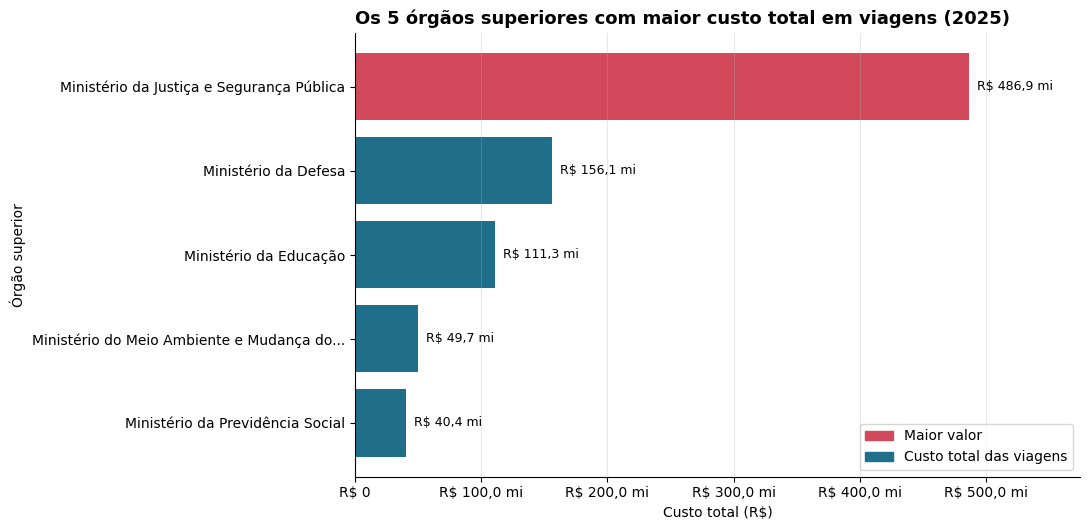

In [5]:
q1["orgao"] = q1["nome_orgao_superior"].apply(lambda t: abreviar(t, 45))
barras_horizontais(
    q1, "orgao", "custo_total",
    titulo="Os 5 órgãos superiores com maior custo total em viagens (2025)",
    xlabel="Custo total (R$)", ylabel="Órgão superior",
    legenda="Custo total das viagens", arquivo="q1_orgaos_custo_total.png",
)

**Leitura:** o Ministério da Justiça e Segurança Pública gastou R$ 486,9 milhões, mais de três vezes o
segundo colocado (Defesa, R$ 156,1 milhões). Os cinco primeiros respondem por cerca de 71% do custo total
das viagens do período (R$ 1,19 bilhão), então a despesa está bem concentrada.

### Pergunta 2: quais são os 3 destinos com maior custo médio por viagem?

O campo `destinos` guarda o roteiro inteiro da viagem (por exemplo, `Brasília/DF, Rio Branco/AC`), então
cada combinação diferente conta como um destino. Primeiro a resposta literal; depois uma versão exigindo
um mínimo de viagens, para não deixar um caso isolado dominar a média.

In [6]:
sql_q2 = """
    SELECT destinos,
           COUNT(*)                      AS qtd_viagens,
           ROUND(AVG(valor_total), 2)    AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    ORDER BY custo_medio DESC
    LIMIT 3
"""
q2 = consultar(sql_q2)
q2

,destinos,qtd_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"245,852.80"
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",1,"216,729.36"
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",1,"207,220.14"


In [7]:
sql_q2b = """
    SELECT destinos,
           COUNT(*)                      AS qtd_viagens,
           ROUND(AVG(valor_total), 2)    AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    HAVING COUNT(*) >= 30
    ORDER BY custo_medio DESC
    LIMIT 3
"""
q2b = consultar(sql_q2b)
q2b

,destinos,qtd_viagens,custo_medio
0,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",91,"105,470.37"
1,"Brasília/DF, Brasília/DF, Brasília/DF",88,"100,317.26"
2,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",47,"97,736.69"


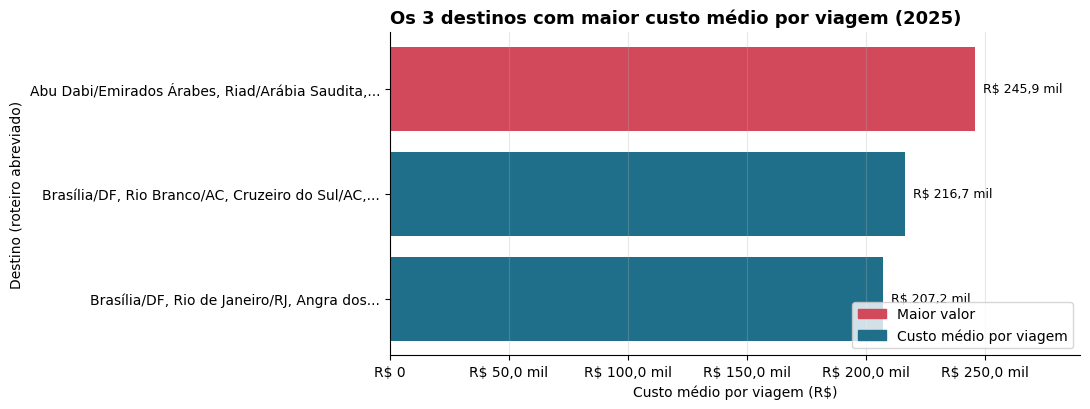

In [8]:
q2["destino"] = q2["destinos"].apply(lambda t: abreviar(t, 50))
barras_horizontais(
    q2, "destino", "custo_medio",
    titulo="Os 3 destinos com maior custo médio por viagem (2025)",
    xlabel="Custo médio por viagem (R$)", ylabel="Destino (roteiro abreviado)",
    legenda="Custo médio por viagem", arquivo="q2_destinos_custo_medio.png",
)

**Leitura:** os três primeiros colocados têm **uma única viagem cada**, com custo entre R$ 207 mil e
R$ 246 mil. Logo, o ranking literal mostra viagens muito caras (a primeira passa por Abu Dabi e Riad), não
um padrão do destino. Exigindo pelo menos 30 viagens, a lista muda: aparecem roteiros com vários trechos em
Brasília, com custo médio acima de R$ 97 mil. Para decisão, a segunda tabela é mais confiável.

### Pergunta 3: qual a viagem de maior duração e qual o seu custo total?

A duração (`duracao_dias`) conta o dia de início e o de fim. Ordenei pelas 10 mais longas para dar contexto.

In [9]:
sql_q3 = """
    SELECT id_viagem, nome_viajante, nome_orgao_superior, destinos,
           data_inicio, data_fim, duracao_dias, situacao, valor_total
    FROM silver_viagem
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 10
"""
q3 = consultar(sql_q3)
q3

,id_viagem,nome_viajante,nome_orgao_superior,destinos,data_inicio,data_fim,duracao_dias,situacao,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,384,Realizada,0.00
1,0000000000020793594,Informações protegidas por sigilo,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-02,2026-01-15,379,Realizada,"120,650.00"
2,0000000000020793492,Informações protegidas por sigilo,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-11,2026-01-15,370,Realizada,"113,382.50"
3,0000000000020774569,CLAUDIA ADRIANA DA SILVA,Ministério da Educação,Bariloche/Argentina,2025-02-26,2026-03-02,370,Realizada,0.00
4,0000000000020592696,RAILANA BERENICE AMORAS OLIVEIRA,Ministério da Justiça e Segurança Pública,"Brasília/DF, Belo Horizonte/MG, Brasília/DF, Fortaleza/CE, Goiânia/GO, Brasí...",2025-01-01,2026-01-02,367,Realizada,"159,044.90"
5,0000000000020685666,STEFANO DOS SANTOS NUNES,Ministério da Justiça e Segurança Pública,"Brasília/DF, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Brasília/DF",2025-01-01,2026-01-02,367,Realizada,"124,312.50"
6,0000000000020732132,GILBERTO SANTOS ANDRADE,Ministério da Educação,Angers/França,2025-03-31,2026-03-31,366,Realizada,0.00
7,0000000000020589962,BRUNO WANDERLEY FRANCA,Ministério da Educação,Aberdeen/Reino Unido,2025-02-23,2026-02-23,366,Realizada,0.00
8,0000000000020557147,JULYANA DOS SANTOS COELHO,Ministério da Justiça e Segurança Pública,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",2025-01-01,2025-12-31,365,Realizada,"216,729.36"
9,0000000000020649880,BRUNO REZENDE CABRAL,Ministério da Justiça e Segurança Pública,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",2025-01-01,2025-12-31,365,Realizada,"207,220.14"


In [10]:
mais_longa = q3.iloc[0]
print(f"Viagem {mais_longa['id_viagem']}: {mais_longa['duracao_dias']} dias "
      f"({mais_longa['data_inicio']:%d/%m/%Y} a {mais_longa['data_fim']:%d/%m/%Y}), "
      f"destino {mais_longa['destinos']}, custo total {reais(mais_longa['valor_total'])}.")

Viagem 0000000000020699856: 384 dias (13/01/2025 a 31/01/2026), destino Mogi Mirim/SP, custo total R$ 0,00.


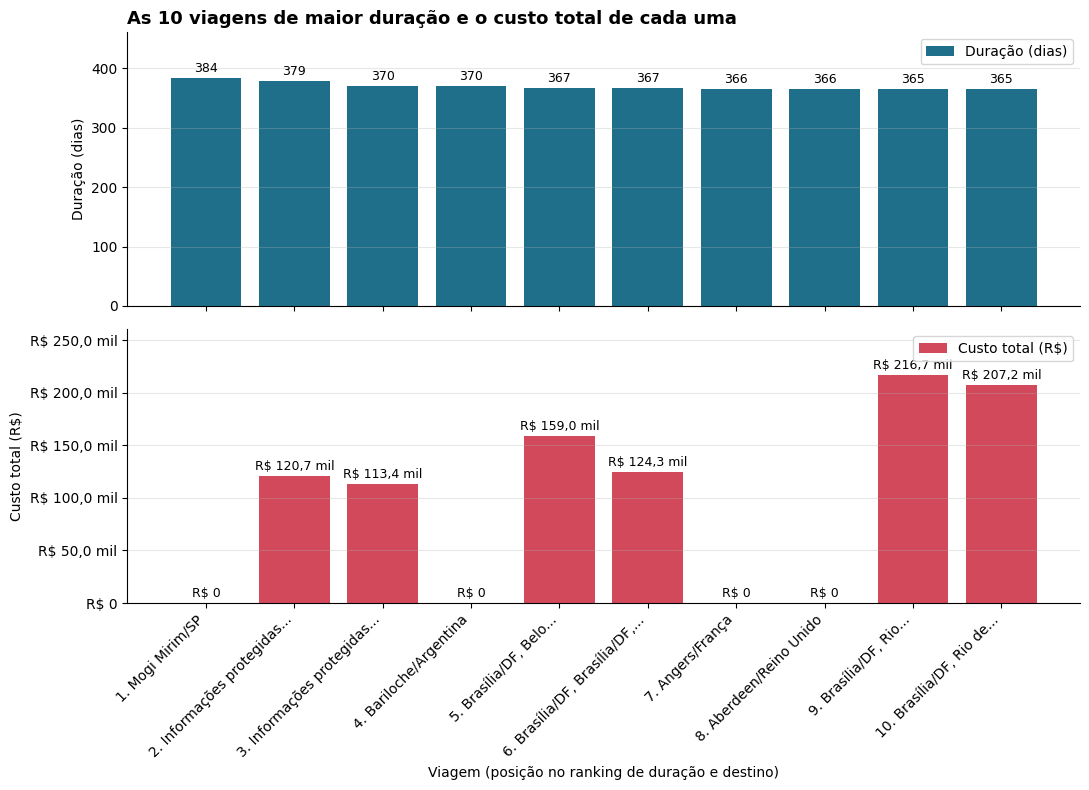

In [11]:
rotulos = [f"{i + 1}. {abreviar(d, 28)}" for i, d in enumerate(q3["destinos"])]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                               gridspec_kw={"height_ratios": [1, 1]})

barras1 = ax1.bar(rotulos, q3["duracao_dias"], color=COR, label="Duração (dias)")
ax1.bar_label(barras1, fmt="%d", fontsize=9, padding=2)
ax1.set_ylabel("Duração (dias)")
ax1.set_ylim(0, q3["duracao_dias"].max() * 1.2)
ax1.legend(loc="upper right")
ax1.set_title("As 10 viagens de maior duração e o custo total de cada uma",
              fontsize=13, fontweight="bold", loc="left")

barras2 = ax2.bar(rotulos, q3["valor_total"], color=COR_DESTAQUE,
                  label="Custo total (R$)")
ax2.bar_label(barras2, labels=[reais_curto(v) for v in q3["valor_total"]],
              fontsize=9, padding=2)
ax2.set_ylabel("Custo total (R$)")
ax2.set_xlabel("Viagem (posição no ranking de duração e destino)")
ax2.set_ylim(0, q3["valor_total"].max() * 1.2)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: reais_curto(v)))
ax2.legend(loc="upper right")
ax2.tick_params(axis="x", rotation=45)
for rotulo in ax2.get_xticklabels():
    rotulo.set_ha("right")

for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("docs/q3_viagens_maior_duracao.png", dpi=130, bbox_inches="tight")
plt.show()

**Leitura:** a viagem mais longa dura **384 dias** (13/01/2025 a 31/01/2026), com destino a Mogi Mirim/SP,
e o custo total registrado é **R$ 0,00**. No top 10 há dois perfis bem diferentes: quatro viagens com
custo zero (a primeira, Bariloche, Aberdeen e Angers) e seis com custo alto, entre R$ 113 mil e
R$ 217 mil, na maior parte em diárias. Ou seja, duração longa não permite concluir nada sobre o gasto, e vale
conferir esses casos antes de usar a duração como medida de esforço ou de custo.

## 3. Camada Gold

Duas tabelas agregadas, cada uma criada com `JOIN` entre tabelas da Silver e `GROUP BY`:

| Tabela / View | Junção | Agrupada por | Métricas |
|---|---|---|---|
| `gold_pagamentos` / `vw_gold_pagamentos` | `silver_pagamento` + `silver_viagem` | órgão superior, órgão pagador, tipo de pagamento | qtd. de pagamentos, qtd. de viagens, valor total, valor médio |
| `gold_trechos` / `vw_gold_trechos` | `silver_trecho` + `silver_viagem` | meio de transporte, UF de destino, situação da viagem | qtd. de trechos, total de diárias |

Cada uma existe como **tabela** (resultado gravado, consulta rápida) e como **VIEW** (sempre recalculada a
partir da Silver). Nas perguntas, usei a tabela em umas e a VIEW em outras.

In [12]:
executar("DROP VIEW IF EXISTS vw_gold_pagamentos")
executar("DROP VIEW IF EXISTS vw_gold_trechos")
executar("DROP TABLE IF EXISTS gold_pagamentos")
executar("DROP TABLE IF EXISTS gold_trechos")

select_pagamentos = """
    SELECT v.nome_orgao_superior,
           p.nome_orgao_pagador,
           p.tipo_pagamento,
           COUNT(*)                    AS qtd_pagamentos,
           COUNT(DISTINCT p.id_viagem) AS qtd_viagens,
           SUM(p.valor)                AS valor_total,
           ROUND(AVG(p.valor), 2)      AS valor_medio
    FROM silver_pagamento p
    JOIN silver_viagem v ON v.id_viagem = p.id_viagem
    GROUP BY v.nome_orgao_superior, p.nome_orgao_pagador, p.tipo_pagamento
"""

select_trechos = """
    SELECT t.meio_transporte,
           t.destino_uf,
           v.situacao,
           COUNT(*)              AS qtd_trechos,
           SUM(t.numero_diarias) AS total_diarias
    FROM silver_trecho t
    JOIN silver_viagem v ON v.id_viagem = t.id_viagem
    GROUP BY t.meio_transporte, t.destino_uf, v.situacao
"""

executar(f"CREATE TABLE gold_pagamentos AS {select_pagamentos}")
executar(f"CREATE VIEW vw_gold_pagamentos AS {select_pagamentos}")
executar(f"CREATE TABLE gold_trechos AS {select_trechos}")
executar(f"CREATE VIEW vw_gold_trechos AS {select_trechos}")

consultar("""
    SELECT 'gold_pagamentos (tabela)' AS objeto, COUNT(*) AS linhas FROM gold_pagamentos
    UNION ALL SELECT 'vw_gold_pagamentos (view)', COUNT(*) FROM vw_gold_pagamentos
    UNION ALL SELECT 'gold_trechos (tabela)', COUNT(*) FROM gold_trechos
    UNION ALL SELECT 'vw_gold_trechos (view)', COUNT(*) FROM vw_gold_trechos
""")

,objeto,linhas
0,gold_trechos (tabela),324
1,gold_pagamentos (tabela),730
2,vw_gold_pagamentos (view),730
3,vw_gold_trechos (view),324


In [13]:
consultar("SELECT * FROM gold_pagamentos ORDER BY valor_total DESC LIMIT 5")

,nome_orgao_superior,nome_orgao_pagador,tipo_pagamento,qtd_pagamentos,qtd_viagens,valor_total,valor_medio
0,Ministério da Justiça e Segurança Pública,Fundo Nacional de Segurança Pública,DIÁRIAS,73474,24035,"265,735,341.14","3,616.73"
1,Ministério da Justiça e Segurança Pública,Sigiloso,DIÁRIAS,71495,49871,"162,972,420.10","2,279.49"
2,Ministério da Defesa,Comando da Aeronáutica,DIÁRIAS,31750,25729,"59,040,684.52","1,859.55"
3,Ministério da Justiça e Segurança Pública,Sigiloso,PASSAGEM,19461,10804,"34,632,600.76","1,779.59"
4,Ministério da Previdência Social,Instituto Nacional do Seguro Social,DIÁRIAS,12028,7192,"31,978,703.47","2,658.69"


In [14]:
consultar("SELECT * FROM gold_trechos ORDER BY qtd_trechos DESC LIMIT 5")

,meio_transporte,destino_uf,situacao,qtd_trechos,total_diarias
0,Aéreo,Distrito Federal,Realizada,60740,"129,908.40"
1,Veículo Oficial,Minas Gerais,Realizada,31753,"27,645.50"
2,Veículo Oficial,São Paulo,Realizada,31086,"24,076.50"
3,Aéreo,São Paulo,Realizada,25862,"25,524.50"
4,Aéreo,Rio de Janeiro,Realizada,24657,"33,076.10"


### Pergunta 4: qual o tipo de pagamento com maior valor médio?

A média correta vem de `SUM(valor_total) / SUM(qtd_pagamentos)`. Tirar a média das médias de cada grupo
distorceria o resultado, porque os grupos têm tamanhos diferentes.

In [15]:
sql_q4 = """
    SELECT tipo_pagamento,
           SUM(qtd_pagamentos)::BIGINT              AS qtd_pagamentos,
           SUM(valor_total)                         AS valor_total,
           ROUND(SUM(valor_total) / SUM(qtd_pagamentos), 2) AS valor_medio
    FROM gold_pagamentos
    GROUP BY tipo_pagamento
    ORDER BY valor_medio DESC
"""
q4 = consultar(sql_q4)
q4

,tipo_pagamento,qtd_pagamentos,valor_total,valor_medio
0,DIÁRIAS,401463,"834,352,643.52","2,078.28"
1,PASSAGEM,188985,"354,978,915.13","1,878.34"
2,Serviço correlato: seguro,4894,"2,190,136.71",447.51
3,RESTITUIÇÃO,11574,"2,843,762.01",245.70


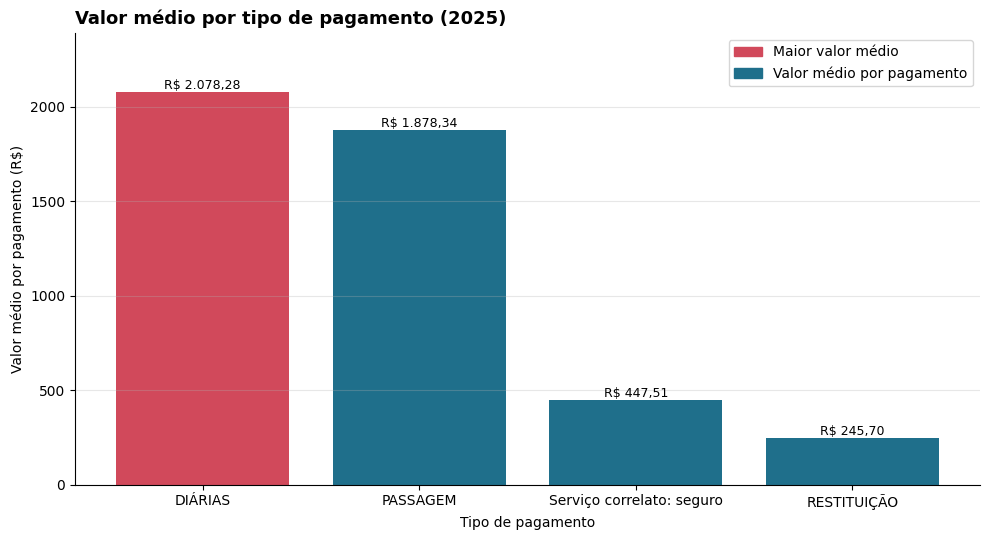

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))
cores = [COR_DESTAQUE] + [COR] * (len(q4) - 1)
barras = ax.bar(q4["tipo_pagamento"], q4["valor_medio"], color=cores,
                label="Valor médio por pagamento")
for barra in barras:
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            reais(barra.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_title("Valor médio por tipo de pagamento (2025)", fontsize=13,
             fontweight="bold", loc="left")
ax.set_xlabel("Tipo de pagamento")
ax.set_ylabel("Valor médio por pagamento (R$)")
ax.set_ylim(0, q4["valor_medio"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=COR_DESTAQUE, label="Maior valor médio"),
                   Patch(color=COR, label="Valor médio por pagamento")],
          loc="upper right")
fig.tight_layout()
fig.savefig("docs/q4_tipo_pagamento_valor_medio.png", dpi=130, bbox_inches="tight")
plt.show()

**Leitura:** **diárias** têm o maior valor médio, R$ 2.078 por pagamento, seguidas de passagens
(R$ 1.878). Seguro e restituição são valores pequenos (R$ 448 e R$ 246 em média). Em volume, diárias
(R$ 834 milhões) e passagens (R$ 355 milhões) concentram praticamente toda a despesa.

### Pergunta 5: qual o meio de transporte mais usado nos trechos?

Aqui uso a **VIEW** `vw_gold_trechos`.

In [17]:
sql_q5 = """
    SELECT meio_transporte,
           SUM(qtd_trechos)::BIGINT AS qtd_trechos,
           ROUND(100.0 * SUM(qtd_trechos) / SUM(SUM(qtd_trechos)) OVER (), 1) AS pct_do_total
    FROM vw_gold_trechos
    GROUP BY meio_transporte
    ORDER BY qtd_trechos DESC
"""
q5 = consultar(sql_q5)
q5

,meio_transporte,qtd_trechos,pct_do_total
0,Veículo Oficial,386424,50.60
1,Aéreo,232666,30.50
2,Rodoviário,64970,8.50
3,Veículo Próprio,42846,5.60
4,Inválido,26659,3.50
5,Fluvial,8429,1.10
6,Ferroviário,874,0.10
7,Marítimo,481,0.10


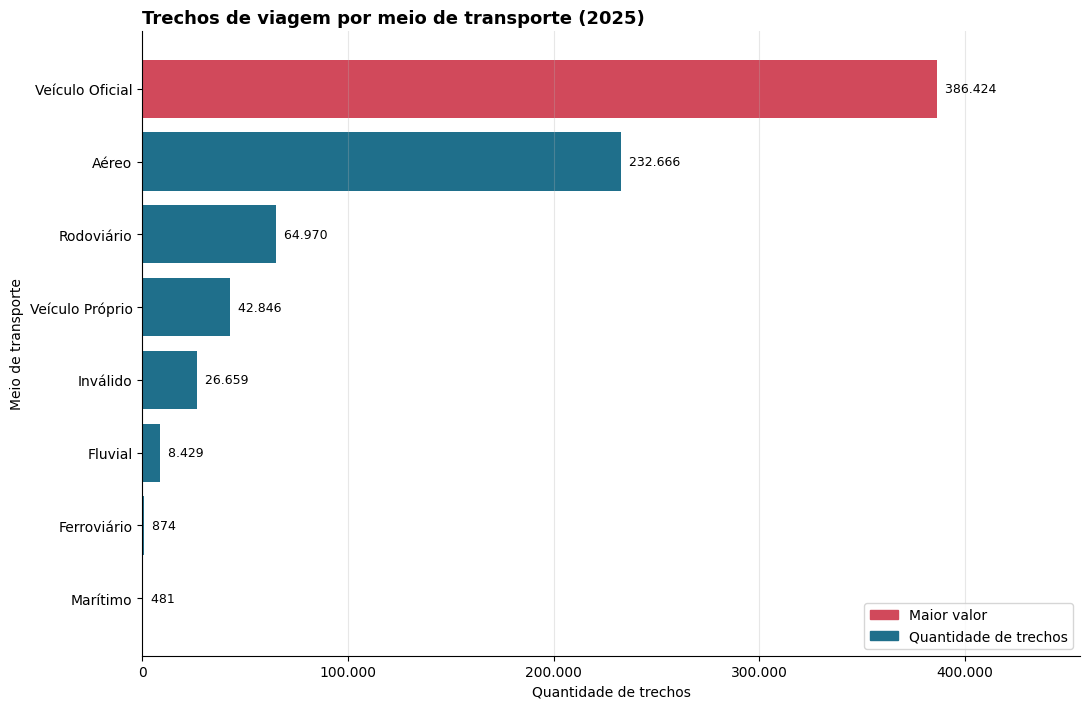

In [18]:
barras_horizontais(
    q5, "meio_transporte", "qtd_trechos",
    titulo="Trechos de viagem por meio de transporte (2025)",
    xlabel="Quantidade de trechos", ylabel="Meio de transporte",
    legenda="Quantidade de trechos", arquivo="q5_meio_transporte_trechos.png",
    formato=inteiro_br,
)

**Leitura:** o **veículo oficial** é o meio mais usado, com 386 mil trechos (50,6% do total), à frente do
aéreo (30,5%). A categoria
"Inválido" (3,5% dos trechos) vem assim da fonte e foi mantida; ela não altera o primeiro lugar.

### Pergunta 6: qual UF de destino aparece em mais trechos?

Também pela **VIEW** `vw_gold_trechos`; o gráfico mostra as 10 primeiras.

In [19]:
sql_q6 = """
    SELECT destino_uf,
           SUM(qtd_trechos)::BIGINT AS qtd_trechos
    FROM vw_gold_trechos
    GROUP BY destino_uf
    ORDER BY qtd_trechos DESC
    LIMIT 10
"""
q6 = consultar(sql_q6)
q6

,destino_uf,qtd_trechos
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


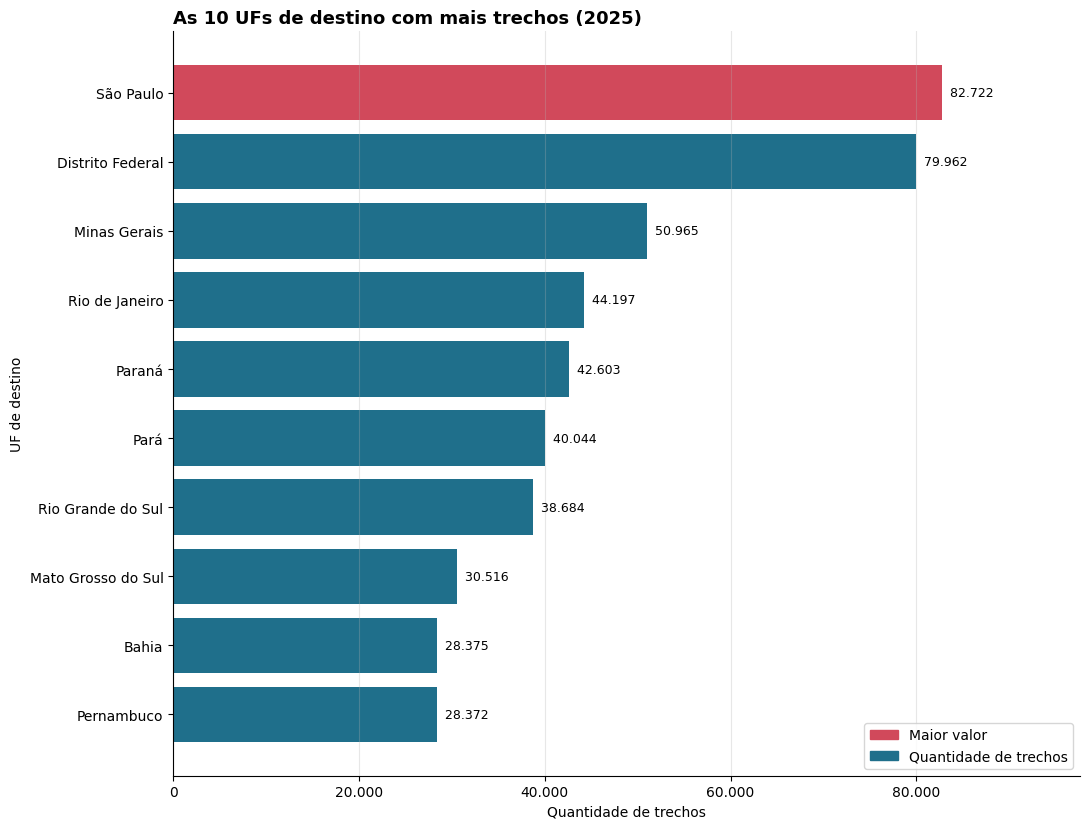

In [20]:
barras_horizontais(
    q6, "destino_uf", "qtd_trechos",
    titulo="As 10 UFs de destino com mais trechos (2025)",
    xlabel="Quantidade de trechos", ylabel="UF de destino",
    legenda="Quantidade de trechos", arquivo="q6_uf_destino_trechos.png",
    formato=inteiro_br,
)

**Leitura:** **São Paulo** lidera, com 82.722 trechos, logo seguido pelo Distrito Federal (79.962). Com
Minas Gerais, as três UFs somam 28% de todos os trechos. O peso do DF é coerente com o fato de ser a sede dos órgãos federais.

### Pergunta 7: qual órgão pagou mais no total?

Aqui é o **órgão pagador** (quem desembolsou), que pode ser diferente do órgão superior da pergunta 1.
Usa a tabela `gold_pagamentos`.

In [21]:
sql_q7 = """
    SELECT nome_orgao_pagador,
           SUM(qtd_pagamentos)::BIGINT AS qtd_pagamentos,
           SUM(valor_total)    AS valor_pago
    FROM gold_pagamentos
    GROUP BY nome_orgao_pagador
    ORDER BY valor_pago DESC
    LIMIT 10
"""
q7 = consultar(sql_q7)
q7

,nome_orgao_pagador,qtd_pagamentos,valor_pago
0,Fundo Nacional de Segurança Pública,79816,"278,481,047.89"
1,Sigiloso,93141,"200,484,801.68"
2,Comando da Aeronáutica,46193,"81,769,144.77"
3,Instituto Nacional do Seguro Social,18324,"37,427,601.45"
4,Comando do Exército,22837,"36,872,643.95"
5,Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com víncu...,20291,"35,541,760.71"
6,Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,16758,"31,589,853.15"
7,Ministério das Relações Exteriores - Unidades com vínculo direto,3705,"25,605,376.38"
8,Receita Federal do Brasil,18917,"23,811,027.00"
9,Ministério da Agricultura e Pecuária - Unidades com vínculo direto,15864,"22,899,880.25"


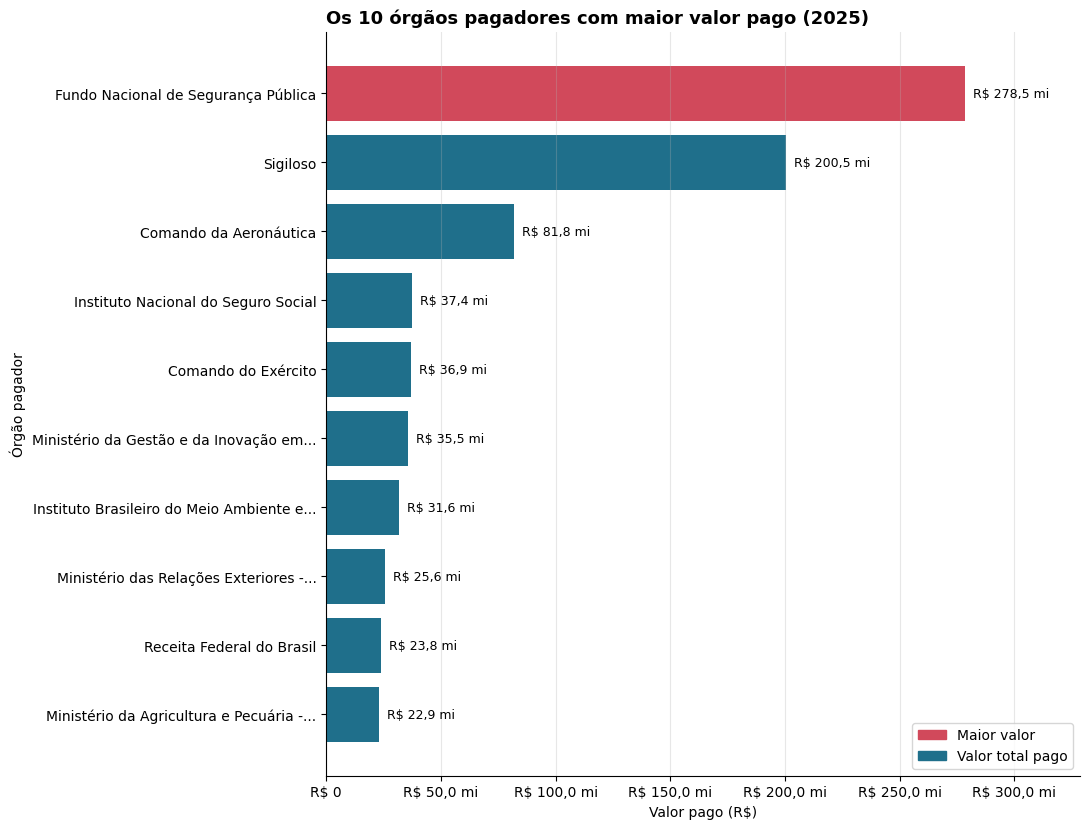

In [22]:
q7["orgao"] = q7["nome_orgao_pagador"].apply(lambda t: abreviar(t, 45))
barras_horizontais(
    q7, "orgao", "valor_pago",
    titulo="Os 10 órgãos pagadores com maior valor pago (2025)",
    xlabel="Valor pago (R$)", ylabel="Órgão pagador",
    legenda="Valor total pago", arquivo="q7_orgaos_pagadores.png",
)

**Leitura:** o **Fundo Nacional de Segurança Pública** pagou mais: R$ 278,5 milhões (23,3% de tudo que foi
pago). Em segundo vem "Sigiloso" (R$ 200,5 milhões), uma categoria da própria fonte que esconde quem
pagou; juntos, os dois representam 40% do total. Isso limita a transparência do dado: uma parte relevante
do gasto não dá para atribuir a um órgão específico.

## Conclusões

- A despesa é concentrada: cinco órgãos superiores ficam com cerca de 71% do custo e um único (Justiça e
  Segurança Pública) com 41%.
- Diárias e passagens são quase toda a despesa, e diárias têm o maior valor médio por pagamento.
- O veículo oficial é o meio de transporte mais usado e São Paulo e Distrito Federal são os destinos
  mais frequentes.
- Duas medidas pedem cuidado: o custo médio por destino (os primeiros colocados são viagens isoladas) e a
  duração (a viagem mais longa tem custo zero, enquanto outras do top 10 passam de R$ 100 mil).
- O Fundo Nacional de Segurança Pública e a categoria "Sigiloso" somam 40% do valor pago, e este último
  não permite identificar o órgão pagador.